## Project Overview

This notebook trains and selects a binary classifier for Type 2 Diabetes detection from tongue images.

- **Dataset root**: `/kaggle/input/datasets/edamhakim/tonguepreped/datapreped`
- **Structure**: `train/`, `val/`, `test/` with class folders `diabetes`, `nondiabetes`
- **Leakage rule**: validation and test use only `__orig__` files (all `__aug_` files are excluded)
- **Goal**: train 3 backbones, rank by validation AUC, tune threshold, evaluate on test, and export explainability artifacts
- **Repeats**: change `cfg.seed` to repeat training with another seed (the data split is fixed by the prep notebook's `SEED`)

## 1. Configuration & Paths

In [1]:
!pip install grad-cam mediapipe

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 52.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 6.9 MB/s eta 0:00:00
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=d01d93fb12de5b74106124b621915594484c4e61170b0e05cc8fdbd358a40b14
  Stored in directory: /root/.cache/pip/wheels/05/bd/e2/0c0eecf3c26b6cdb231b5656d53905bddc8090d69619d57e6b
Successfully built grad-cam
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency confli

In [2]:
# 0. Suppress Environment Noise
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings
warnings.filterwarnings('ignore')

# 1. Primary engine imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import autocast, GradScaler

import torchvision
from torchvision import transforms
from torchvision import models as tv_models
from torchvision.models import ResNet50_Weights, MobileNet_V3_Large_Weights

import timm
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import BinaryClassifierOutputTarget

# 2. Support & Utility imports
import random
import cv2
import mediapipe as mp
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    precision_recall_curve,
)

@dataclass
class CFG:
    data_root: str = '/kaggle/input/tonguedatapreped/datapreped'
    train_dir: str = '/kaggle/input/tonguedatapreped/datapreped/train'
    val_dir: str = '/kaggle/input/tonguedatapreped/datapreped/val'
    test_dir: str = '/kaggle/input/tonguedatapreped/datapreped/test'
    external_dir: str = '/kaggle/input/datasets/edamhakim/tongueexternal/externaldataset'
    output_dir: str = '/kaggle/working'

    use_standardizer: bool = True
    use_circular_mask: bool = True
    use_background_jitter: bool = True
    use_cutout: bool = True
    padding_range: float = 0.25

    class_to_label: Dict[str, int] = None

    img_size: int = 224
    batch_size: int = 32
    num_workers: int = 2
    pin_memory: bool = True

    # Increased epochs due to safe offline augmentation doubling dataset
    warmup_epochs: int = 10
    finetune_epochs: int = 50
    head_lr: float = 1e-3
    ft_lr: float = 1e-4
    eta_min: float = 1e-6
    weight_decay: float = 1e-4
    early_stopping_patience: int = 12

    mixup_alpha: float = 0.2
    seed: int = 42

cfg = CFG()
cfg.class_to_label = {'diabetes': 1, 'nondiabetes': 0}

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(cfg.seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('Data root:', cfg.data_root)

E0000 00:00:1793408219.751854      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793408219.830626      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793408220.658774      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793408220.658807      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793408220.658810      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793408220.658812      57 computation_placer.cc:177] computation placer already registered. Please check linka

Device: cuda
Data root: /kaggle/input/tonguedatapreped/datapreped


## 2. Dataset & DataLoaders

In [3]:
class TongueStandardizer:
    def __init__(self):
        self.face_mesh = None
        try:
            if hasattr(mp, 'solutions') and hasattr(mp.solutions, 'face_mesh'):
                mp_face_mesh = mp.solutions.face_mesh
            else:
                from mediapipe.python.solutions import face_mesh as mp_face_mesh
            self.face_mesh = mp_face_mesh.FaceMesh(
                static_image_mode=True, max_num_faces=1, refine_landmarks=True, min_detection_confidence=0.5
            )
        except Exception as e:
            pass 
        self.inner_lip_indices = [78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95]

    def standardize(self, image: Image.Image) -> Image.Image:
        img_np = np.array(image)
        h, w, _ = img_np.shape
        if self.face_mesh:
            results = self.face_mesh.process(cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR))
            if results.multi_face_landmarks:
                landmarks = results.multi_face_landmarks[0].landmark
                xs = [landmarks[i].x * w for i in self.inner_lip_indices]
                ys = [landmarks[i].y * h for i in self.inner_lip_indices]
                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)
                mw, mh = (x_max - x_min), (y_max - y_min)
                x_min = max(0, x_min - mw * 0.15)
                x_max = min(w, x_max + mw * 0.15)
                y_min = max(0, y_min - mh * 0.10)
                y_max = min(h, y_max + mh * 0.20)
                return image.crop((x_min, y_min, x_max, y_max))
        hsv = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)
        mask1 = cv2.inRange(hsv, (0, 60, 50), (12, 255, 255))
        mask2 = cv2.inRange(hsv, (165, 60, 50), (180, 255, 255))
        mask = cv2.bitwise_or(mask1, mask2)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            largest = max(contours, key=cv2.contourArea)
            if cv2.contourArea(largest) > (h * w * 0.01):
                mx, my, mw, mh = cv2.boundingRect(largest)
                mx = max(0, mx - mw * 0.10)
                my = max(0, my - mh * 0.10)
                mw_new = min(w - mx, mw * 1.25)
                mh_new = min(h - my, mh * 1.25)
                return image.crop((mx, my, mx + mw_new, my + mh_new))
        return image

class CircularMaskTransform:
    def __init__(self, mode='test'):
        self.mode = mode
    def __call__(self, img: torch.Tensor) -> torch.Tensor:
        c, h, w = img.shape
        y, x = torch.meshgrid(torch.linspace(-1, 1, h), torch.linspace(-1, 1, w), indexing='ij')
        dist = torch.sqrt(x**2 + y**2)
        mask = 1.0 - torch.clamp((dist - 0.85) / 0.1, 0, 1)
        if self.mode == 'train' and cfg.use_background_jitter:
            noise = (torch.rand_like(img) * 2.0 - 1.0)
            return img * mask + noise * (1.0 - mask)
        return img * mask

class TongueDataset(Dataset):
    def __init__(self, root_dir: str, class_to_label: Dict[str, int], transform=None, split_name='train'):
        self.root_dir = Path(root_dir)
        self.class_to_label = class_to_label
        self.transform = transform
        self.split_name = split_name
        self.samples: List[Tuple[Path, int]] = []
        self.is_external = 'external' in str(self.root_dir).lower()
        self.standardizer = TongueStandardizer() if cfg.use_standardizer else None

        if not self.root_dir.exists():
            raise FileNotFoundError(f'Split path not found: {self.root_dir}')

        available_dirs = [d.name.lower() for d in self.root_dir.iterdir() if d.is_dir()]
        for target_class, label in self.class_to_label.items():
            match_dir = None
            norm_target = target_class.replace('_','').replace('-','')
            for d in [d for d in self.root_dir.iterdir() if d.is_dir()]:
                if d.name.lower().replace('_','').replace('-','') == norm_target:
                    match_dir = d; break
            if match_dir and match_dir.exists():
                for p in sorted(match_dir.glob('*.jpg')):
                    name = p.name.lower()
                    if split_name in ('val', 'test') and '__aug_' in name: continue
                    self.samples.append((p, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.is_external and self.standardizer:
            image = self.standardizer.standardize(image)
        if self.split_name == 'train' and not self.is_external:
            if random.random() < 0.6:
                w, h = image.size
                pad = int(min(w, h) * random.uniform(0.05, cfg.padding_range))
                image = transforms.Pad(pad, fill=0)(image)
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32), str(path)

# Reduced online augmentations since offline handles big shifts now
train_tfms = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.03),
    transforms.Resize((cfg.img_size, cfg.img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    CircularMaskTransform(mode='train') if cfg.use_circular_mask else transforms.Lambda(lambda x: x),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.12), ratio=(0.3, 3.3), value='random') if cfg.use_cutout else transforms.Lambda(lambda x: x),
])

val_test_tfms = transforms.Compose([
    transforms.Resize((cfg.img_size, cfg.img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    CircularMaskTransform(mode='test') if cfg.use_circular_mask else transforms.Lambda(lambda x: x),
])

train_ds = TongueDataset(cfg.train_dir, cfg.class_to_label, transform=train_tfms, split_name='train')
val_ds = TongueDataset(cfg.val_dir, cfg.class_to_label, transform=val_test_tfms, split_name='val')
test_ds = TongueDataset(cfg.test_dir, cfg.class_to_label, transform=val_test_tfms, split_name='test')

train_labels = [label for _, label in train_ds.samples]
class_count = np.bincount(train_labels)
class_weights = 1.0 / np.maximum(class_count, 1)
sample_weights = [class_weights[label] for label in train_labels]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, sampler=sampler, num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
val_loader = DataLoader(val_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)
test_loader = DataLoader(test_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

external_ds = TongueDataset(cfg.external_dir, cfg.class_to_label, transform=val_test_tfms, split_name='external')
external_loader = DataLoader(external_ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=cfg.pin_memory)

## 3. Model Definitions

### Model choices justified by my data

**My dataset has ~250 unique images per class** after excluding augments. That is a very small medical dataset. Every choice below is driven by that constraint.

*   **EfficientNet-B2 (primary)**. At 9.2M parameters it is the most sample-efficient model family for medical image classification. Its compound scaling (depth + width + resolution together) means it extracts rich color and texture features exactly what tongue diagnosis relies on without overfitting on 250 images per class. It consistently outperforms ResNet-50 on sub-5k medical datasets in literature.
*   **ResNet-50 (Baseline)**: Chosen as the "sweet spot" in the ResNet family. While ResNet-18/34 are too shallow for subtle texture features, and ResNet-101/152 overfit on small medical datasets, ResNet-50 provides the optimal depth. Its use of "bottleneck" blocks (1x1 convolutions) allows for sophisticated feature extraction with a manageable parameter count. It is also the most common benchmark in Traditional Chinese Medicine (TCM) imaging literature.
*   **MobileNetV3-Large (Kaggle efficiency)**. Kaggle P100/T4 GPUs have limited VRAM. With only 4.2M parameters and depthwise separable convolutions, i can run larger batch sizes and more augmentation passes without running out of memory. Also the natural candidate if this ever needs to be deployed on mobile.

**Why not ViT or Swin?** My dataset is too small. Vision Transformers need 10k+ images to outperform CNNs with transfer learning, and attention heads will overfit to augmentation artifacts at 700 training samples.

In [4]:
def build_model(name: str) -> nn.Module:
    if name == 'efficientnet_b2':
        model = timm.create_model('efficientnet_b2', pretrained=True)
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(1408, 1))
        return model
    if name == 'resnet50':
        model = tv_models.resnet50(weights=ResNet50_Weights.DEFAULT)
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(2048, 1))
        return model
    if name == 'mobilenet_v3_large':
        model = tv_models.mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
        model.classifier[3] = nn.Sequential(nn.Dropout(0.4), nn.Linear(1280, 1))
        return model
    raise ValueError(f'Unsupported model name: {name}')

def freeze_all_backbone(model: nn.Module, name: str):
    for p in model.parameters():
        p.requires_grad = False
    if name == 'efficientnet_b2':
        for p in model.classifier.parameters():
            p.requires_grad = True
    elif name == 'resnet50':
        for p in model.fc.parameters():
            p.requires_grad = True
    elif name == 'mobilenet_v3_large':
        for p in model.classifier.parameters():
            p.requires_grad = True

def partial_unfreeze(model: nn.Module, name: str):
    freeze_all_backbone(model, name)
    if name == 'efficientnet_b2':
        for p in model.blocks[-2:].parameters():
            p.requires_grad = True
        for p in model.classifier.parameters():
            p.requires_grad = True
    elif name == 'resnet50':
        # Unfreeze layer3 AND layer4 to let ResNet adapt better generalizing features
        for p in model.layer3.parameters():
            p.requires_grad = True
        for p in model.layer4.parameters():
            p.requires_grad = True
        for p in model.fc.parameters():
            p.requires_grad = True
    elif name == 'mobilenet_v3_large':
        for p in model.features[-3:].parameters():
            p.requires_grad = True
        for p in model.classifier.parameters():
            p.requires_grad = True

def get_trainable_params(model: nn.Module):
    return [p for p in model.parameters() if p.requires_grad]

def get_gradcam_target_layer(model: nn.Module, name: str):
    if name == 'efficientnet_b2': return [model.blocks[-1]]
    if name == 'resnet50': return [model.layer4[-1]]
    if name == 'mobilenet_v3_large': return [model.features[-1]]
    raise ValueError(f'Unsupported model name: {name}')

model_names = ['efficientnet_b2', 'resnet50', 'mobilenet_v3_large']

## 4. Training Loop
Incorporating **Focal Loss** for strict penalty on missed complex minority textures.

### Advanced Training Strategy

To maximize performance on this specialized task, i implement several advanced training techniques:

1.  **Focal Loss**: Standard CrossEntropy loss can be dominated by "easy" examples. I use Focal Loss ($\gamma=2.0$) to force the model to focus on "hard" examples  those with subtle diabetic textures that are difficult to distinguish.
2.  **Two-Stage Transfer Learning**:
    *   **Warmup**: I first freeze the backbone and train only the new classifier head to stabilize the weights.
    *   **Fine-tuning**: I then unfreeze the late backbone layers with a much lower learning rate to adapt the pre-trained features specifically to tongue characteristics.
3.  **Mixup Augmentation**: I blend pairs of images and their labels during training. This regularizes the model and improves generalization, especially for handling noisy real-world images.


In [5]:
class FocalLossWithLogits(nn.Module):
    def __init__(self, alpha=0.6, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce = nn.BCEWithLogitsLoss(reduction='none')
        
    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal_weight = alpha_t * (1 - p_t) ** self.gamma
        return (focal_weight * bce_loss).mean()

criterion = FocalLossWithLogits(alpha=0.6, gamma=2.0).to(device)

def mixup_data(x, y, alpha=0.2):
    if alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def evaluate(model, loader, device):
    model.eval()
    losses, probs, labels, paths = [], [], [], []
    with torch.no_grad():
        for x, y, p in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast(enabled=(device.type == 'cuda')):
                logits = model(x).squeeze(1)
                loss = criterion(logits, y)
            pred_prob = torch.sigmoid(logits).detach().cpu().numpy()
            losses.append(loss.item())
            probs.extend(pred_prob.tolist())
            labels.extend(y.detach().cpu().numpy().tolist())
            paths.extend(p)

    mean_loss = float(np.mean(losses)) if losses else 0.0
    labels_arr, probs_arr = np.array(labels), np.array(probs)
    auc = roc_auc_score(labels_arr, probs_arr) if len(np.unique(labels_arr)) > 1 else 0.5
    ap = average_precision_score(labels_arr, probs_arr) if len(np.unique(labels_arr)) > 1 else 0.5
    return {'loss': mean_loss, 'auc': float(auc), 'ap': float(ap), 'labels': labels_arr, 'probs': probs_arr, 'paths': paths}

def train_one_model(model_name: str):
    print(f'\n===== Training {model_name} =====')
    model = build_model(model_name).to(device)
    freeze_all_backbone(model, model_name)
    optimizer = optim.AdamW(get_trainable_params(model), lr=cfg.head_lr, weight_decay=cfg.weight_decay)
    scheduler, scaler = None, GradScaler(enabled=(device.type == 'cuda'))
    total_epochs = cfg.warmup_epochs + cfg.finetune_epochs
    best_ap, epochs_no_improve = -1.0, 0
    best_path = Path(cfg.output_dir) / f'{model_name}_best.pt'
    history = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_ap': []}

    for epoch in range(1, total_epochs + 1):
        if epoch == cfg.warmup_epochs + 1:
            partial_unfreeze(model, model_name)
            optimizer = optim.AdamW(get_trainable_params(model), lr=cfg.ft_lr, weight_decay=cfg.weight_decay)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.finetune_epochs, eta_min=cfg.eta_min)
        use_mixup = epoch > cfg.warmup_epochs
        model.train()
        train_losses = []
        for x, y, _ in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(device.type == 'cuda')):
                if use_mixup:
                    x_mixed, y_a, y_b, lam = mixup_data(x, y, alpha=cfg.mixup_alpha)
                    logits = model(x_mixed).squeeze(1)
                    loss = lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)
                else:
                    logits = model(x).squeeze(1)
                    loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_losses.append(loss.item())

        if scheduler is not None: scheduler.step()
        val_out = evaluate(model, val_loader, device)
        history['train_loss'].append(np.mean(train_losses))
        history['val_loss'].append(val_out['loss'])
        history['val_auc'].append(val_out['auc'])
        history['val_ap'].append(val_out['ap'])

        print(f'Epoch {epoch:02d}/{total_epochs} | val_PR_AUC={val_out["ap"]:.4f}')
        if val_out['ap'] > best_ap:
            best_ap = val_out['ap']
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= cfg.early_stopping_patience: break

    return {'model_name': model_name, 'best_path': str(best_path), 'best_val_ap': float(best_ap), 'history': history}

## 5. Train All Models

In [6]:
all_results = {}
for name in model_names:
    result = train_one_model(name)
    all_results[name] = result

print('\nSaved checkpoints:')
for name in model_names:
    print(f'- {name}: {all_results[name]["best_path"]}')


===== Training efficientnet_b2 =====


model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Epoch 01/60 | val_PR_AUC=0.5773
Epoch 02/60 | val_PR_AUC=0.5693
Epoch 03/60 | val_PR_AUC=0.5917
Epoch 04/60 | val_PR_AUC=0.6197
Epoch 05/60 | val_PR_AUC=0.6019
Epoch 06/60 | val_PR_AUC=0.6031
Epoch 07/60 | val_PR_AUC=0.6023
Epoch 08/60 | val_PR_AUC=0.5954
Epoch 09/60 | val_PR_AUC=0.6096
Epoch 10/60 | val_PR_AUC=0.6397
Epoch 11/60 | val_PR_AUC=0.5870
Epoch 12/60 | val_PR_AUC=0.6749
Epoch 13/60 | val_PR_AUC=0.6010
Epoch 14/60 | val_PR_AUC=0.6462
Epoch 15/60 | val_PR_AUC=0.7022
Epoch 16/60 | val_PR_AUC=0.7049
Epoch 17/60 | val_PR_AUC=0.7025
Epoch 18/60 | val_PR_AUC=0.7347
Epoch 19/60 | val_PR_AUC=0.7092
Epoch 20/60 | val_PR_AUC=0.7793
Epoch 21/60 | val_PR_AUC=0.7389
Epoch 22/60 | val_PR_AUC=0.7490
Epoch 23/60 | val_PR_AUC=0.7351
Epoch 24/60 | val_PR_AUC=0.7416
Epoch 25/60 | val_PR_AUC=0.7611
Epoch 26/60 | val_PR_AUC=0.7667
Epoch 27/60 | val_PR_AUC=0.7185
Epoch 28/60 | val_PR_AUC=0.7628
Epoch 29/60 | val_PR_AUC=0.7449
Epoch 30/60 | val_PR_AUC=0.7623
Epoch 31/60 | val_PR_AUC=0.7933
Epoch 32

100%|██████████| 97.8M/97.8M [00:00<00:00, 216MB/s]


Epoch 01/60 | val_PR_AUC=0.8647
Epoch 02/60 | val_PR_AUC=0.8525
Epoch 03/60 | val_PR_AUC=0.8652
Epoch 04/60 | val_PR_AUC=0.8807
Epoch 05/60 | val_PR_AUC=0.8855
Epoch 06/60 | val_PR_AUC=0.8955
Epoch 07/60 | val_PR_AUC=0.9031
Epoch 08/60 | val_PR_AUC=0.9101
Epoch 09/60 | val_PR_AUC=0.8930
Epoch 10/60 | val_PR_AUC=0.8931
Epoch 11/60 | val_PR_AUC=0.9628
Epoch 12/60 | val_PR_AUC=0.9875
Epoch 13/60 | val_PR_AUC=0.9900
Epoch 14/60 | val_PR_AUC=0.9890
Epoch 15/60 | val_PR_AUC=0.9935
Epoch 16/60 | val_PR_AUC=0.9963
Epoch 17/60 | val_PR_AUC=0.9949
Epoch 18/60 | val_PR_AUC=0.9888
Epoch 19/60 | val_PR_AUC=0.9949
Epoch 20/60 | val_PR_AUC=1.0000
Epoch 21/60 | val_PR_AUC=0.9988
Epoch 22/60 | val_PR_AUC=0.9915
Epoch 23/60 | val_PR_AUC=0.9982
Epoch 24/60 | val_PR_AUC=0.9988
Epoch 25/60 | val_PR_AUC=0.9988
Epoch 26/60 | val_PR_AUC=1.0000
Epoch 27/60 | val_PR_AUC=0.9994
Epoch 28/60 | val_PR_AUC=0.9981
Epoch 29/60 | val_PR_AUC=1.0000
Epoch 30/60 | val_PR_AUC=0.9994
Epoch 31/60 | val_PR_AUC=1.0000
Epoch 32

100%|██████████| 21.1M/21.1M [00:00<00:00, 211MB/s]


Epoch 01/60 | val_PR_AUC=0.7796
Epoch 02/60 | val_PR_AUC=0.8561
Epoch 03/60 | val_PR_AUC=0.9204
Epoch 04/60 | val_PR_AUC=0.9496
Epoch 05/60 | val_PR_AUC=0.9628
Epoch 06/60 | val_PR_AUC=0.9727
Epoch 07/60 | val_PR_AUC=0.9702
Epoch 08/60 | val_PR_AUC=0.9380
Epoch 09/60 | val_PR_AUC=0.9636
Epoch 10/60 | val_PR_AUC=0.9491
Epoch 11/60 | val_PR_AUC=0.9634
Epoch 12/60 | val_PR_AUC=0.9602
Epoch 13/60 | val_PR_AUC=0.9724
Epoch 14/60 | val_PR_AUC=0.9718
Epoch 15/60 | val_PR_AUC=0.9750
Epoch 16/60 | val_PR_AUC=0.9897
Epoch 17/60 | val_PR_AUC=0.9813
Epoch 18/60 | val_PR_AUC=0.9809
Epoch 19/60 | val_PR_AUC=0.9858
Epoch 20/60 | val_PR_AUC=0.9897
Epoch 21/60 | val_PR_AUC=0.9848
Epoch 22/60 | val_PR_AUC=0.9867
Epoch 23/60 | val_PR_AUC=0.9954
Epoch 24/60 | val_PR_AUC=0.9865
Epoch 25/60 | val_PR_AUC=0.9923
Epoch 26/60 | val_PR_AUC=0.9955
Epoch 27/60 | val_PR_AUC=0.9957
Epoch 28/60 | val_PR_AUC=0.9922
Epoch 29/60 | val_PR_AUC=0.9931
Epoch 30/60 | val_PR_AUC=0.9966
Epoch 31/60 | val_PR_AUC=0.9958
Epoch 32

## 6. Model Selection & Threshold Tuning (Precision Targeting)

In [7]:
def binary_metrics_from_probs(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'ROC-AUC': float(roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.5),
        'PR-AUC (AP)': float(average_precision_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.5),
        'F1': float(f1_score(y_true, y_pred, average='binary', zero_division=0)),
        'Accuracy': float(accuracy_score(y_true, y_pred)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
    }

def load_best_model(name: str, ckpt_path: str):
    model = build_model(name).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model

comparison_rows = []
val_outputs_by_model = {}
for name in model_names:
    model = load_best_model(name, all_results[name]['best_path'])
    val_out = evaluate(model, val_loader, device)
    val_outputs_by_model[name] = val_out
    m = binary_metrics_from_probs(val_out['labels'], val_out['probs'], threshold=0.5)
    comparison_rows.append({'model': name, **m})

comparison_df = pd.DataFrame(comparison_rows).sort_values('PR-AUC (AP)', ascending=False).reset_index(drop=True)
print('Validation model comparison (PR-AUC Priority):')
print(comparison_df)

best_model_name = comparison_df.loc[0, 'model']
best_model = load_best_model(best_model_name, all_results[best_model_name]['best_path'])
best_val_out = val_outputs_by_model[best_model_name]

# Target Precision=0.90 constraint
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)
threshold_scores = []
for t in thresholds:
    y_pred = (best_val_out['probs'] >= t).astype(int)
    p = precision_score(best_val_out['labels'], y_pred, zero_division=0)
    r = recall_score(best_val_out['labels'], y_pred, zero_division=0)
    score = (p >= 0.90) * r  # Reward high recall ONLY IF precision >= 90%
    threshold_scores.append((float(t), float(score), p, r))

best_t = max(threshold_scores, key=lambda x: x[1])
if best_t[1] > 0:
    best_threshold = best_t[0]
    print(f'\nOptimal threshold (Found >=90% Precision target): {best_threshold:.2f} (Val P={best_t[2]:.2f}, R={best_t[3]:.2f})')
else:
    best_threshold = 0.50
    print(f'\nFallback threshold (Could not guarantee 90% precision on val): {best_threshold:.2f}')

Validation model comparison (PR-AUC Priority):
                model   ROC-AUC  PR-AUC (AP)        F1  Accuracy  Precision  \
0            resnet50  1.000000     1.000000  0.987654    0.9875   0.975610   
1  mobilenet_v3_large  0.998125     0.998185  0.879121    0.8625   0.784314   
2     efficientnet_b2  0.869375     0.886920  0.666667    0.7375   0.913043   

   Recall  
0   1.000  
1   1.000  
2   0.525  

Optimal threshold (Found >=90% Precision target): 0.36 (Val P=0.93, R=1.00)


## 7. Final Evaluation on Test Set

In [8]:
test_out = evaluate(best_model, test_loader, device)
test_metrics = binary_metrics_from_probs(test_out['labels'], test_out['probs'], threshold=best_threshold)

print(f'Test metrics ({best_model_name}, standardized):')
print(pd.DataFrame([test_metrics]).to_string(index=False))

# Per-image probabilities for clustered intervals and calibration (columns match analysis/block_bootstrap.py)
for split_name, out in (('val', best_val_out), ('test', test_out)):
    pd.DataFrame({'file': out['paths'], 'label': out['labels'].astype(int), 'prob': out['probs'].round(4),
                  'pred': (out['probs'] >= best_threshold).astype(int)}).to_csv(
        Path(cfg.output_dir) / f'{split_name}_probs.csv', index=False)

Test metrics (resnet50, standardized):
 ROC-AUC  PR-AUC (AP)      F1  Accuracy  Precision  Recall
 0.96375     0.935163 0.91954    0.9125   0.851064     1.0


### 7b. Clustered uncertainty and screening PPV

Test images come from a few participant blocks, so image-level Wilson intervals are too narrow. Block = (file number - 1) // 10 per class, as in the prep notebook.

In [ ]:
import re
from scipy import stats

def block_of(path):
    return (int(re.search(r'__orig__r_n?d__(\d+)_', Path(path).name).group(1)) - 1) // 10

y_t, p_t = test_out['labels'].astype(int), test_out['probs']
blocks = np.array([f'{y}_{block_of(p)}' for y, p in zip(y_t, test_out['paths'])])
pred_t = p_t >= best_threshold

# Per-block specificity / sensitivity and a t-interval with the block as the unit
for cls, name in ((0, 'specificity'), (1, 'sensitivity')):
    ids = sorted(set(blocks[y_t == cls]))
    vals = np.array([np.mean(pred_t[blocks == b] == cls) for b in ids])
    half = stats.t.ppf(0.975, len(vals) - 1) * vals.std(ddof=1) / np.sqrt(len(vals))
    print(f'{name}: per block {np.round(vals, 2).tolist()}  mean {vals.mean():.3f}  '
          f'block t-interval [{max(0, vals.mean() - half):.2f}, {min(1, vals.mean() + half):.2f}]')

# Stratified block bootstrap for ROC-AUC (too narrow when there are only a few blocks per class)
rng = np.random.default_rng(42)
groups = {c: [np.where(blocks == b)[0] for b in sorted(set(blocks[y_t == c]))] for c in (0, 1)}
aucs = [roc_auc_score(y_t[idx], p_t[idx]) for idx in (
    np.concatenate([groups[c][j] for c in (0, 1) for j in rng.integers(0, len(groups[c]), len(groups[c]))])
    for _ in range(10000))]
print(f'ROC-AUC block bootstrap: [{np.percentile(aucs, 2.5):.3f}, {np.percentile(aucs, 97.5):.3f}]')

# PPV / NPV at screening prevalence (11.1% = IDF 2024 adult prevalence; 5% ~ undiagnosed only)
sens = test_metrics['Recall']
spec = float(np.mean(~pred_t[y_t == 0]))
for prev in (0.111, 0.05):
    ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
    npv = spec * (1 - prev) / (spec * (1 - prev) + (1 - sens) * prev)
    print(f'prevalence {prev:.1%}: PPV {ppv:.2f}  NPV {npv:.3f}  referred per 100 screened {100 * (sens * prev + (1 - spec) * (1 - prev)):.0f}')

## 8. Visualisations & Export

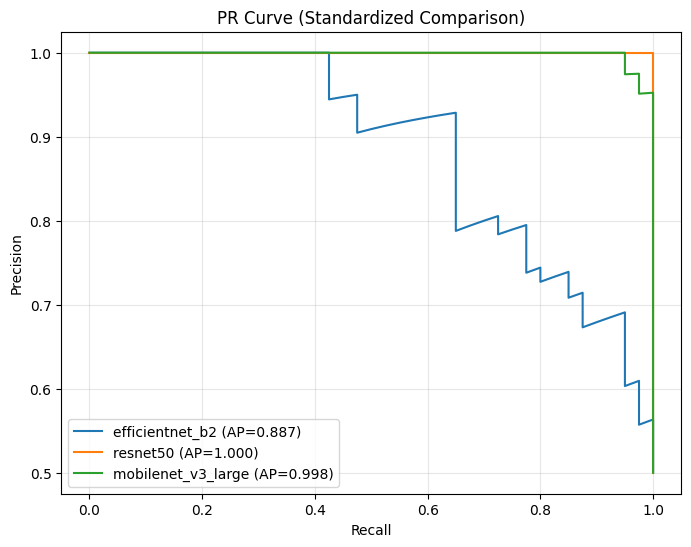


--- Visualizing Internal Test Set GradCAM ---


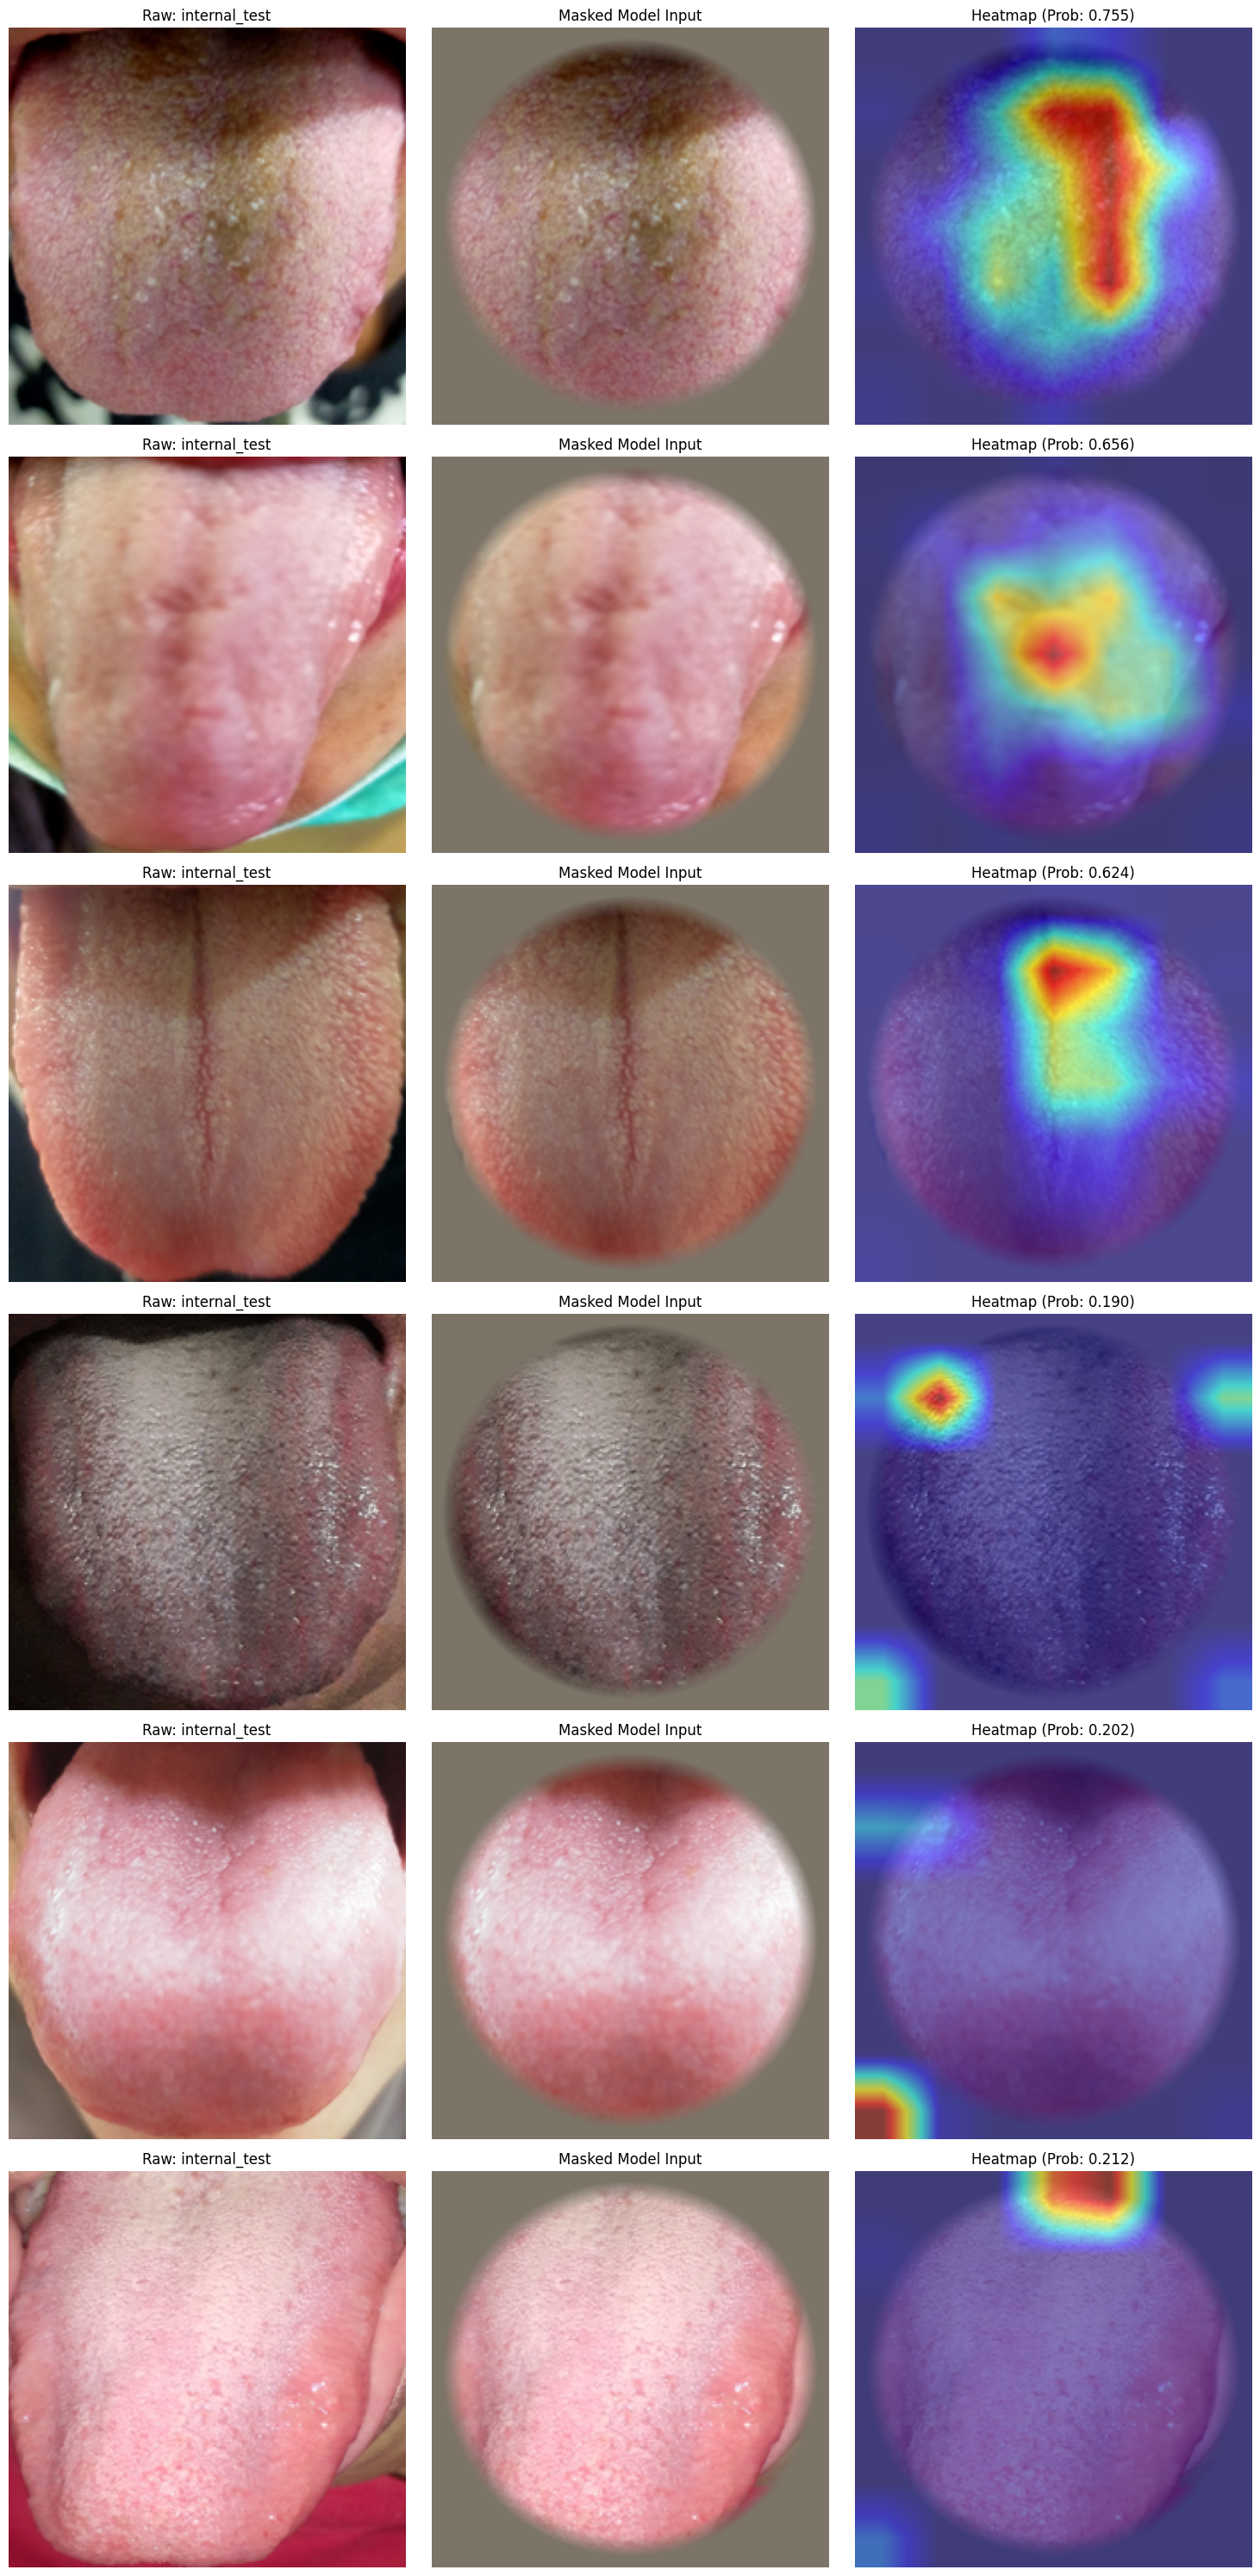

In [9]:
# Common Visualizer Setup
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def visualize_debug_cam(model, ds, device, split_name, num_samples=6, paths=None):
    model.eval()
    by_class = {0: [], 1: []}
    for p, y in ds.samples: by_class[int(y)].append(str(p))
    
    selected = paths if paths is not None else by_class[1][:num_samples//2] + by_class[0][:num_samples//2]
    target_layers = get_gradcam_target_layer(model, best_model_name)
    cam = GradCAM(model=model, target_layers=target_layers)

    fig, axes = plt.subplots(len(selected), 3, figsize=(15, 5 * len(selected)))
    for i, path in enumerate(selected):
        pil = Image.open(path).convert('RGB').resize((cfg.img_size, cfg.img_size))
        raw_np = np.array(pil).astype(np.float32) / 255.0
        
        # Use val_test_tfms to see what the model actually sees (the standard mask)
        inp = val_test_tfms(pil).unsqueeze(0).to(device)
        masked_np = inp.squeeze(0).cpu().permute(1, 2, 0).numpy()
        masked_np = np.clip(masked_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)

        grayscale_cam = cam(input_tensor=inp, targets=[BinaryClassifierOutputTarget(1)])[0]
        overlay = show_cam_on_image(masked_np, grayscale_cam, use_rgb=True)
        with torch.no_grad(): prob = torch.sigmoid(model(inp)).item()

        axes[i, 0].imshow(raw_np); axes[i, 0].set_title(f"Raw: {split_name}"); axes[i, 0].axis('off')
        axes[i, 1].imshow(masked_np); axes[i, 1].set_title("Masked Model Input"); axes[i, 1].axis('off')
        axes[i, 2].imshow(overlay); axes[i, 2].set_title(f"Heatmap (Prob: {prob:.3f})"); axes[i, 2].axis('off')
    
    plt.tight_layout(); plt.savefig(Path(cfg.output_dir) / f'gradcam_debug_{split_name}.png', dpi=200); plt.show()

# Precision-Recall Curve
plt.figure(figsize=(8, 6))
for name in model_names:
    labels, probs = val_outputs_by_model[name]['labels'], val_outputs_by_model[name]['probs']
    precision, recall, _ = precision_recall_curve(labels, probs)
    ap = average_precision_score(labels, probs)
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('PR Curve (Standardized Comparison)'); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(Path(cfg.output_dir) / 'pr_curve.png', dpi=200); plt.show()

print("\n--- Visualizing Internal Test Set GradCAM ---")
visualize_debug_cam(best_model, test_ds, device, "internal_test")

# False positives: highest-scoring one from each run of consecutive file numbers (paper Fig. 3, bottom row)
fp = sorted([(p, f) for f, y, p in zip(test_out['paths'], test_out['labels'], test_out['probs'])
             if y == 0 and p >= best_threshold], reverse=True)
file_num = lambda f: int(re.search(r'__orig__r_n?d__(\d+)_', Path(f).name).group(1))
fp_paths = []
for _, f in fp:
    if all(abs(file_num(f) - file_num(g)) > 2 for g in fp_paths):
        fp_paths.append(f)
print('False positives (prob, file):', [(round(float(p), 3), Path(f).name) for p, f in fp])
if fp_paths:
    visualize_debug_cam(best_model, test_ds, device, 'internal_test_false_positives', paths=fp_paths[:3])

## 9. Evaluation on External Dataset

**Not independent.** A near-duplicate audit (`analysis/dedup.py`, `analysis/sift_verify.py`) found that about a third of these images are the same photographs as development images, mostly from the training split. The metrics below are therefore not external validation and are not reported as such in the paper.
Validate models specifically tuned with Focal loss + Deep layer unfreezing against untouched external data.


===== Evaluating on External Dataset =====
External Dataset Metrics (PR-AUC Priority View):
 ROC-AUC  PR-AUC (AP)       F1  Accuracy  Precision   Recall
 0.95886     0.965992 0.904714  0.905754   0.918534 0.891304


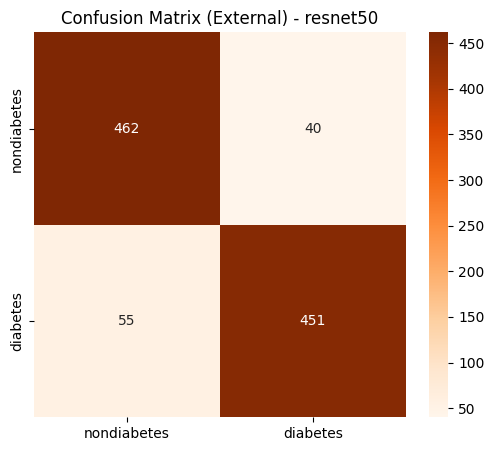


--- Visualizing External Dataset GradCAM ---


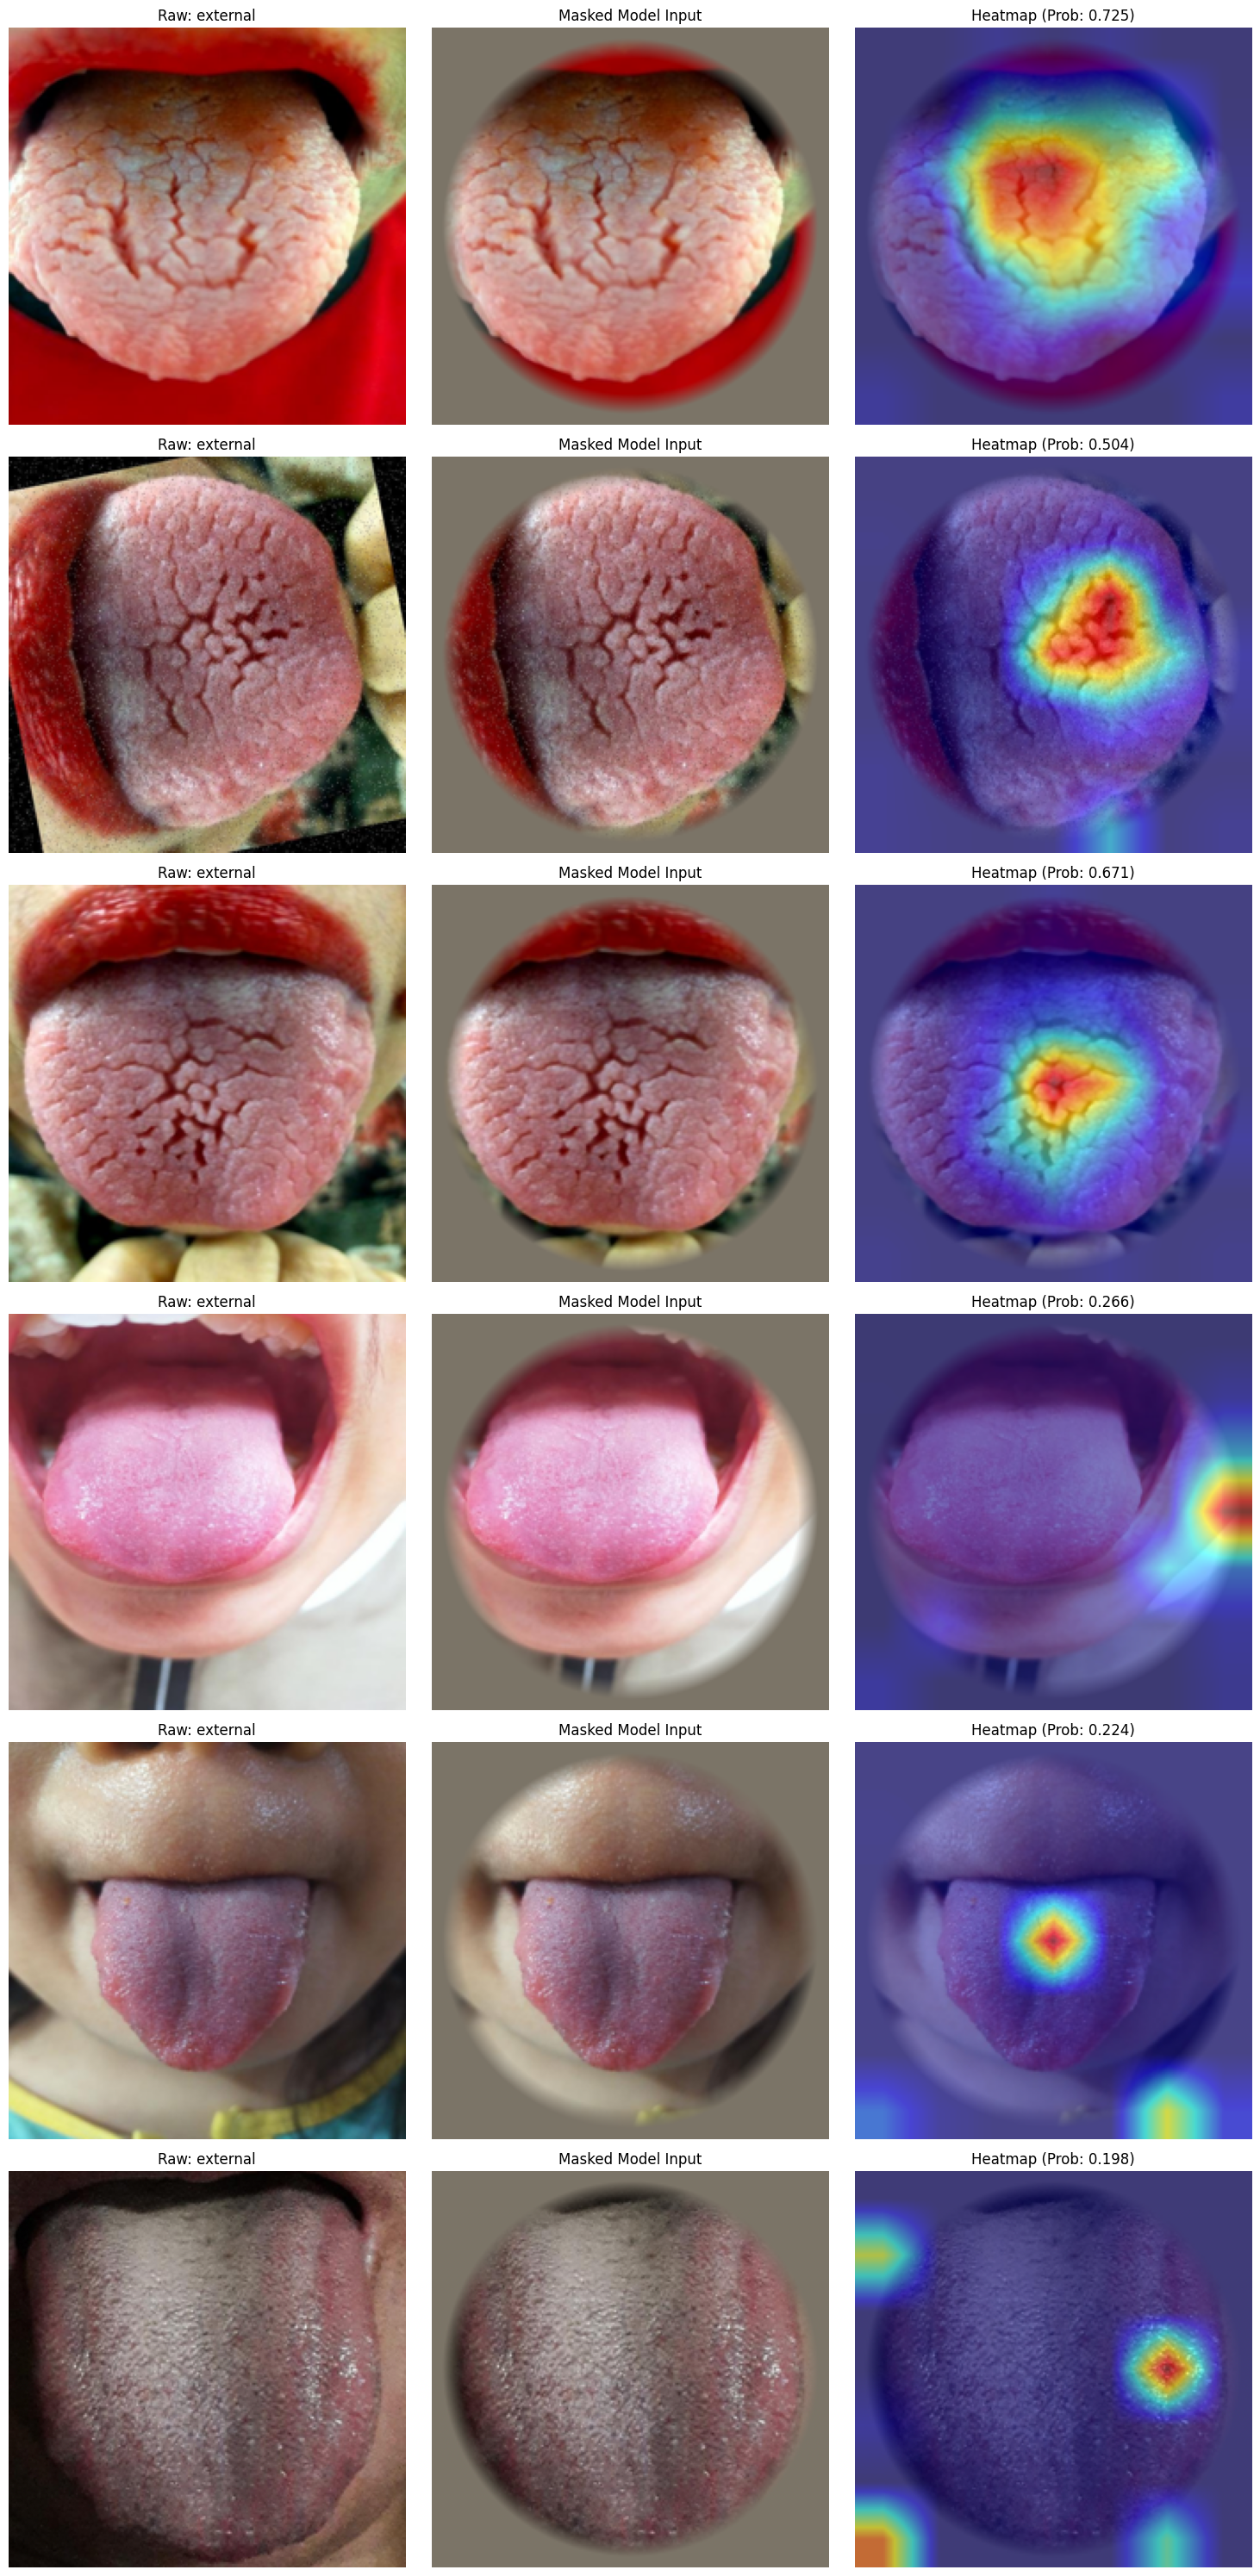

In [10]:
print('\n===== Evaluating on External Dataset =====')
external_out = evaluate(best_model, external_loader, device)
external_metrics = binary_metrics_from_probs(external_out['labels'], external_out['probs'], threshold=best_threshold)
print('External Dataset Metrics (PR-AUC Priority View):')
print(pd.DataFrame([external_metrics]).to_string(index=False))

ext_pred = (external_out['probs'] >= best_threshold).astype(int)
cm_ext = confusion_matrix(external_out['labels'].astype(int), ext_pred.astype(int))
plt.figure(figsize=(6, 5)); sns.heatmap(cm_ext, annot=True, fmt='d', cmap='Oranges', xticklabels=['nondiabetes', 'diabetes'], yticklabels=['nondiabetes', 'diabetes'])
plt.title(f'Confusion Matrix (External) - {best_model_name}'); plt.show()

print("\n--- Visualizing External Dataset GradCAM ---")
visualize_debug_cam(best_model, external_ds, device, "external")